# ขั้นที่ 1: ตั้งคำถามสำหรับการวิเคราะห์ (World Energy Consumption)

เป้าหมายของขั้นนี้คือ **รู้จักข้อมูลมากพอที่จะตั้งคำถามที่ข้อมูลตอบได้จริง** ยังไม่ต้องทำความสะอาดหรือวิเคราะห์ลึก

ลำดับในโน้ตบุ๊กนี้:
1. โหลดข้อมูลและดูภาพรวม
2. ดูว่า "หนึ่งแถว" คืออะไร
3. แยกประเทศจริงออกจากกลุ่มภูมิภาค
4. จัดกลุ่มคอลัมน์ให้อ่านง่าย
5. เช็กว่าข้อมูลมีช่วงปีไหนบ้าง
6. ดูกราฟคร่าว ๆ เพื่อหาไอเดียคำถาม
7. **เขียนคำถามของเรา** แล้วให้ Python ช่วยเช็กว่าข้อมูลพอตอบหรือไม่

> วางไฟล์ `World_Energy_Consumption.csv` ไว้โฟลเดอร์เดียวกับโน้ตบุ๊กนี้ แล้วกด Run ทีละเซลล์ (Shift + Enter)

## 1. โหลดข้อมูลและดูภาพรวม

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

df = pd.read_csv("World_Energy_Consumption.csv")
print("จำนวนแถว x คอลัมน์:", df.shape)
df.head()

จำนวนแถว x คอลัมน์: (22012, 129)


,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,biofuel_electricity,biofuel_share_elec,biofuel_share_energy,carbon_intensity_elec,coal_cons_change_pct,coal_cons_change_twh,coal_cons_per_capita,coal_consumption,coal_elec_per_capita,coal_electricity,coal_prod_change_pct,coal_prod_change_twh,coal_prod_per_capita,coal_production,coal_share_elec,...,primary_energy_consumption,renewables_cons_change_pct,renewables_cons_change_twh,renewables_consumption,renewables_elec_per_capita,renewables_electricity,renewables_energy_per_capita,renewables_share_elec,renewables_share_energy,solar_cons_change_pct,solar_cons_change_twh,solar_consumption,solar_elec_per_capita,solar_electricity,solar_energy_per_capita,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.60,1.519,NaN,500.231,NaN,NaN,NaN,NaN,NaN,71.03,NaN,NaN,NaN,NaN,19.268,...,NaN,NaN,NaN,NaN,NaN,72.90,NaN,19.775,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.02,1.516,NaN,499.358,NaN,NaN,NaN,NaN,NaN,80.02,NaN,NaN,NaN,NaN,20.147,...,NaN,NaN,NaN,NaN,NaN,76.68,NaN,19.306,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.06,1.433,NaN,505.652,NaN,NaN,NaN,NaN,NaN,87.16,NaN,NaN,NaN,NaN,20.614,...,NaN,NaN,NaN,NaN,NaN,75.99,NaN,17.972,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.69,1.496,NaN,513.698,NaN,NaN,NaN,NaN,NaN,98.51,NaN,NaN,NaN,NaN,22.031,...,NaN,NaN,NaN,NaN,NaN,75.71,NaN,16.932,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.57,1.561,NaN,520.910,NaN,NaN,NaN,NaN,NaN,111.62,NaN,NaN,NaN,NaN,23.017,...,NaN,NaN,NaN,NaN,NaN,77.02,NaN,15.882,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN


## 2. หนึ่งแถวคืออะไร
ถ้าคู่ `country` + `year` ไม่ซ้ำกันเลย แปลว่า **1 แถว = 1 ประเทศ ใน 1 ปี**

In [2]:
print("แถวซ้ำ (country + year):", df.duplicated(["country", "year"]).sum())
print("ช่วงปี:", df["year"].min(), "-", df["year"].max())
print("จำนวนชื่อในคอลัมน์ country:", df["country"].nunique())

แถวซ้ำ (country + year): 0
ช่วงปี: 1900 - 2022
จำนวนชื่อในคอลัมน์ country: 306


## 3. แยกประเทศจริงออกจากกลุ่มภูมิภาค
คอลัมน์ `country` มีทั้งประเทศและกลุ่มอย่าง "Asia", "ASEAN (Ember)", "High-income countries" ปนกัน
ถ้าไม่แยก เวลารวมยอดจะ **นับซ้ำ** ทันที วิธีง่ายที่สุดคือดูว่ามี `iso_code` หรือไม่

In [3]:
is_country = df["iso_code"].notna()
countries = df[is_country]
aggregates = df[~is_country]

print("ประเทศ (มี iso_code):", countries["country"].nunique())
print("กลุ่ม/ภูมิภาค/อื่น ๆ (ไม่มี iso_code):", aggregates["country"].nunique())
print()
print("ตัวอย่างชื่อที่ไม่มี iso_code:")
print(sorted(aggregates["country"].unique()))

ประเทศ (มี iso_code): 219
กลุ่ม/ภูมิภาค/อื่น ๆ (ไม่มี iso_code): 87

ตัวอย่างชื่อที่ไม่มี iso_code:
['ASEAN (Ember)', 'Africa', 'Africa (EI)', 'Africa (Ember)', 'Africa (Shift)', 'Asia', 'Asia & Oceania (EIA)', 'Asia (Ember)', 'Asia Pacific (EI)', 'Asia and Oceania (Shift)', 'Australia and New Zealand (EIA)', 'CIS (EI)', 'Central & South America (EIA)', 'Central America (EI)', 'Central and South America (Shift)', 'Czechoslovakia', 'EU28 (Shift)', 'East Germany (EIA)', 'Eastern Africa (EI)', 'Eurasia (EIA)', 'Eurasia (Shift)', 'Europe', 'Europe (EI)', 'Europe (Ember)', 'Europe (Shift)', 'European Union (27)', 'European Union (EIA)', 'G20 (Ember)', 'G7 (Ember)', 'Hawaiian Trade Zone (EIA)', 'High-income countries', 'IEO - Africa (EIA)', 'IEO - Middle East (EIA)', 'IEO OECD - Europe (EIA)', 'Kosovo', 'Latin America and Caribbean (Ember)', 'Low-income countries', 'Lower-middle-income countries', 'Mexico, Chile, and other OECD Americas (EIA)', 'Middle Africa (EI)', 'Middle East (EI)', 'Midd

> ลองไล่ดูรายชื่อด้านบน บางชื่อเป็นประเทศจริงที่ไม่มีรหัส เช่น Kosovo หรือประเทศที่ไม่มีแล้ว เช่น Czechoslovakia ให้จดไว้ว่าจะจัดการอย่างไรในขั้นทำความสะอาด

## 4. จัดกลุ่มคอลัมน์ให้อ่านง่าย
ชื่อคอลัมน์ตั้งเป็นแบบ **ชื่อเชื้อเพลิง + ส่วนท้าย** เราจะแยกออกมาเป็นตาราง

In [4]:
SUFFIXES = {
    "_share_elec": "สัดส่วนในการผลิตไฟฟ้า (%)",
    "_share_energy": "สัดส่วนในพลังงานทั้งหมด (%)",
    "_elec_per_capita": "ไฟฟ้าต่อคน (kWh)",
    "_energy_per_capita": "พลังงานต่อคน (kWh)",
    "_cons_per_capita": "การใช้ต่อคน (kWh)",
    "_prod_per_capita": "การผลิตต่อคน (kWh)",
    "_cons_change_pct": "การใช้ เปลี่ยนจากปีก่อน (%)",
    "_cons_change_twh": "การใช้ เปลี่ยนจากปีก่อน (TWh)",
    "_prod_change_pct": "การผลิต เปลี่ยนจากปีก่อน (%)",
    "_prod_change_twh": "การผลิต เปลี่ยนจากปีก่อน (TWh)",
    "_consumption": "ปริมาณการใช้ (TWh)",
    "_electricity": "ไฟฟ้าที่ผลิตได้ (TWh)",
    "_production": "ปริมาณการผลิต (TWh)",
}

rows = []
for col in df.columns:
    for suf, meaning in SUFFIXES.items():
        if col.endswith(suf):
            rows.append({"คอลัมน์": col, "เชื้อเพลิง": col[: -len(suf)], "ความหมาย": meaning})
            break
    else:
        rows.append({"คอลัมน์": col, "เชื้อเพลิง": "-", "ความหมาย": "คอลัมน์ทั่วไป"})

col_info = pd.DataFrame(rows)
col_info["ข้อมูลว่าง (%)"] = (df.isna().mean() * 100).round(1).values

# สรุปว่าแต่ละความหมายมีเชื้อเพลิงอะไรบ้าง
col_info.groupby("ความหมาย")["เชื้อเพลิง"].apply(lambda s: ", ".join(s)).to_frame()

,เชื้อเพลิง
ความหมาย,
การผลิต เปลี่ยนจากปีก่อน (%),"coal, gas, oil"
การผลิต เปลี่ยนจากปีก่อน (TWh),"coal, gas, oil"
การผลิตต่อคน (kWh),"coal, gas, oil"
การใช้ เปลี่ยนจากปีก่อน (%),"biofuel, coal, energy, fossil, gas, hydro, low..."
การใช้ เปลี่ยนจากปีก่อน (TWh),"biofuel, coal, energy, fossil, gas, hydro, low..."
การใช้ต่อคน (kWh),"biofuel, coal"
คอลัมน์ทั่วไป,"-, -, -, -, -, -, -, -, -, -, -, -, -, -, -"
ปริมาณการผลิต (TWh),"coal, gas, oil"
ปริมาณการใช้ (TWh),"biofuel, coal, fossil_fuel, gas, hydro, low_ca..."


In [5]:
# คอลัมน์ทั่วไป และคอลัมน์ที่ว่างมาก (เกิน 80%) ซึ่งไม่ควรใช้ตั้งคำถาม
display(col_info[col_info["ความหมาย"] == "คอลัมน์ทั่วไป"])
display(col_info[col_info["ข้อมูลว่าง (%)"] > 80].sort_values("ข้อมูลว่าง (%)", ascending=False))

,คอลัมน์,เชื้อเพลิง,ความหมาย,ข้อมูลว่าง (%)
0,country,-,คอลัมน์ทั่วไป,0.0
1,year,-,คอลัมน์ทั่วไป,0.0
2,iso_code,-,คอลัมน์ทั่วไป,25.0
3,population,-,คอลัมน์ทั่วไป,17.7
4,gdp,-,คอลัมน์ทั่วไป,49.5
13,carbon_intensity_elec,-,คอลัมน์ทั่วไป,76.5
26,electricity_demand,-,คอลัมน์ทั่วไป,74.3
27,electricity_generation,-,คอลัมน์ทั่วไป,67.3
31,energy_per_capita,-,คอลัมน์ทั่วไป,51.8
32,energy_per_gdp,-,คอลัมน์ทั่วไป,67.2


,คอลัมน์,เชื้อเพลิง,ความหมาย,ข้อมูลว่าง (%)
5,biofuel_cons_change_pct,biofuel,การใช้ เปลี่ยนจากปีก่อน (%),92.1
113,solar_cons_change_pct,solar,การใช้ เปลี่ยนจากปีก่อน (%),90.4
7,biofuel_cons_per_capita,biofuel,การใช้ต่อคน (kWh),89.5
121,wind_cons_change_pct,wind,การใช้ เปลี่ยนจากปีก่อน (%),89.0
72,nuclear_cons_change_pct,nuclear,การใช้ เปลี่ยนจากปีก่อน (%),88.8
12,biofuel_share_energy,biofuel,สัดส่วนในพลังงานทั้งหมด (%),87.9
6,biofuel_cons_change_twh,biofuel,การใช้ เปลี่ยนจากปีก่อน (TWh),87.8
8,biofuel_consumption,biofuel,ปริมาณการใช้ (TWh),87.4
95,other_renewables_cons_change_pct,other_renewables,การใช้ เปลี่ยนจากปีก่อน (%),83.9
77,nuclear_energy_per_capita,nuclear,พลังงานต่อคน (kWh),82.8


> หน่วยในตารางนี้เป็นการอ่านจากชื่อคอลัมน์ ควรยืนยันกับ codebook ของ Our World in Data อีกครั้ง

## 5. ข้อมูลมีช่วงปีไหนบ้าง
แม้ไฟล์จะเริ่มปี 1900 แต่ข้อมูลไฟฟ้าเริ่มทีหลังมาก ต้องรู้ก่อนตั้งคำถามเรื่องช่วงเวลา

In [6]:
KEY_COLS = ["population", "gdp", "primary_energy_consumption", "electricity_generation",
            "electricity_demand", "per_capita_electricity", "gas_share_elec", "solar_share_elec"]

th = df[df["country"] == "Thailand"]
coverage = pd.DataFrame({
    "ปีแรกที่มีข้อมูล": [th.loc[th[c].notna(), "year"].min() for c in KEY_COLS],
    "ปีสุดท้าย": [th.loc[th[c].notna(), "year"].max() for c in KEY_COLS],
    "จำนวนปี": [th[c].notna().sum() for c in KEY_COLS],
}, index=KEY_COLS)
print("ประเทศไทย:")
coverage

ประเทศไทย:


,ปีแรกที่มีข้อมูล,ปีสุดท้าย,จำนวนปี
population,1900,2022,123
gdp,1913,2018,72
primary_energy_consumption,1965,2022,58
electricity_generation,1985,2022,38
electricity_demand,2000,2022,23
per_capita_electricity,1985,2022,38
gas_share_elec,1985,2022,38
solar_share_elec,1985,2022,38


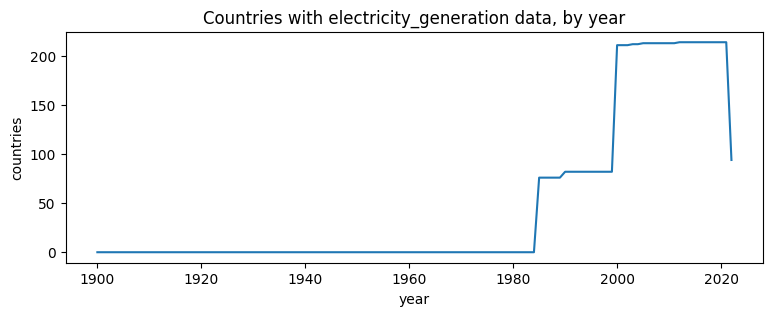

In [7]:
# ทั้งโลก: แต่ละปีมีกี่ประเทศที่มีข้อมูลการผลิตไฟฟ้า
n = countries.groupby("year")["electricity_generation"].count()
n.plot(figsize=(9, 3), title="Countries with electricity_generation data, by year")
plt.ylabel("countries"); plt.show()

## 6. ดูกราฟคร่าว ๆ เพื่อหาไอเดียคำถาม
ยังไม่ต้องสวย แค่ดูว่าอะไรน่าสนใจ (ใช้ชื่อแกนภาษาอังกฤษเพื่อเลี่ยงปัญหาฟอนต์ไทยใน matplotlib)

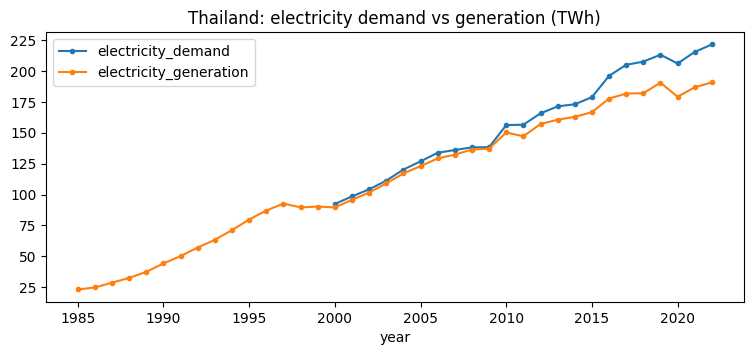

ปีล่าสุด:       electricity_demand  electricity_generation
year                                            
2022              221.59                  190.88


In [8]:
# 6.1 ไทย: ความต้องการไฟฟ้า vs ไฟฟ้าที่ผลิตเอง
th_e = th.set_index("year")[["electricity_demand", "electricity_generation"]].loc[1985:]
th_e.plot(figsize=(9, 3.5), marker=".", title="Thailand: electricity demand vs generation (TWh)")
plt.show()
print("ปีล่าสุด:", th_e.dropna().tail(1))

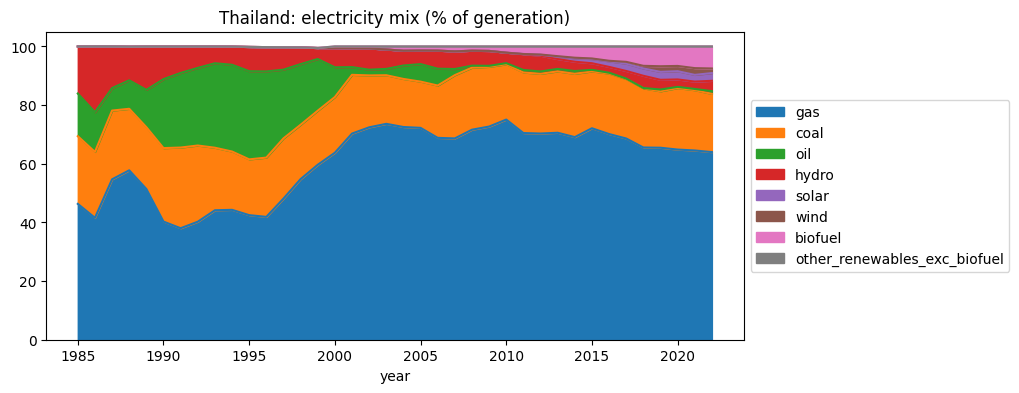

In [9]:
# 6.2 ไทย: ผลิตไฟฟ้าจากเชื้อเพลิงอะไร (สัดส่วน %)
FUELS = ["gas", "coal", "oil", "hydro", "solar", "wind", "biofuel", "other_renewable_exc_biofuel"]
mix_cols = [f"{f}_share_elec" for f in FUELS if f"{f}_share_elec" in df.columns]
mix_cols += [c for c in ["other_renewables_share_elec_exc_biofuel"] if c in df.columns]
mix = th.set_index("year")[mix_cols].loc[1985:].dropna(how="all")
mix.columns = [c.replace("_share_elec", "") for c in mix.columns]
mix.plot.area(figsize=(9, 4), title="Thailand: electricity mix (% of generation)")
plt.legend(loc="center left", bbox_to_anchor=(1, .5)); plt.show()

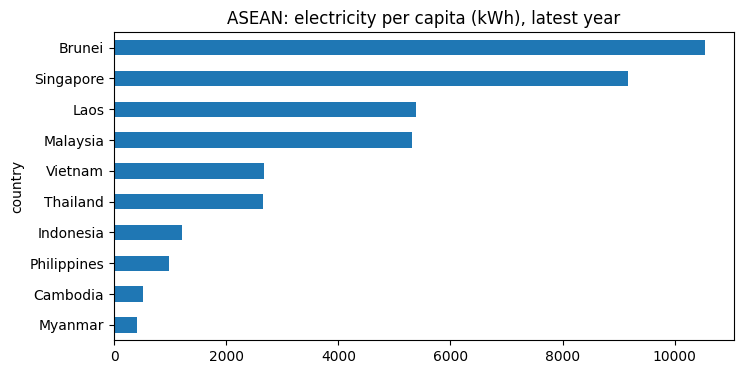

,country,year,per_capita_electricity
3139,Brunei,2021,10530.286
3528,Cambodia,2021,523.840
9411,Indonesia,2022,1210.666
10574,Laos,2021,5383.125
11555,Malaysia,2022,5318.783
12893,Myanmar,2021,415.628
16331,Philippines,2022,975.605
17635,Singapore,2022,9168.817
19403,Thailand,2022,2662.314
21318,Vietnam,2022,2681.927


In [10]:
# 6.3 เทียบอาเซียน: ใช้ไฟต่อคน ปีล่าสุดที่มีข้อมูล
ASEAN = ["Thailand", "Vietnam", "Malaysia", "Indonesia", "Philippines",
         "Singapore", "Myanmar", "Cambodia", "Laos", "Brunei"]
a = df[df["country"].isin(ASEAN)].dropna(subset=["per_capita_electricity"])
latest = a.loc[a.groupby("country")["year"].idxmax(), ["country", "year", "per_capita_electricity"]]
latest.sort_values("per_capita_electricity").plot.barh(
    x="country", y="per_capita_electricity", legend=False, figsize=(8, 4),
    title="ASEAN: electricity per capita (kWh), latest year")
plt.show()
latest

## 7. เขียนคำถามของเรา ✍️

คำถามที่ดีควร **เจาะจง** (ประเทศไหน ช่วงปีไหน วัดด้วยอะไร) และ **ข้อมูลตอบได้**

แก้ `QUESTIONS` ด้านล่างให้เป็นคำถามของคุณเอง โดยใส่ให้แต่ละคำถาม:
- `question`: คำถามเป็นภาษาไทย
- `countries`: ประเทศที่เกี่ยวข้อง
- `years`: ช่วงปี (เริ่ม, สิ้นสุด)
- `columns`: คอลัมน์ที่ต้องใช้ตอบ (ดูชื่อจากตารางข้อ 4)

แล้ว Run เซลล์ถัดไปเพื่อเช็กว่าข้อมูลพอตอบหรือไม่

In [11]:
QUESTIONS = [
    {
        "question": "ความต้องการไฟฟ้าของไทยเพิ่มขึ้นกี่เปอร์เซ็นต์ระหว่างปี 2000-2022",
        "countries": ["Thailand"],
        "years": (2000, 2022),
        "columns": ["electricity_demand"],
    },
    {
        "question": "สัดส่วนพลังงานหมุนเวียนในการผลิตไฟฟ้าของไทยเปลี่ยนไปอย่างไร (1990-2022)",
        "countries": ["Thailand"],
        "years": (1990, 2022),
        "columns": ["renewables_share_elec", "solar_share_elec", "wind_share_elec", "hydro_share_elec"],
    },
    {
        "question": "ไทยพึ่งพาก๊าซธรรมชาติในการผลิตไฟฟ้ามากกว่าเพื่อนบ้านอาเซียนหรือไม่",
        "countries": ["Thailand", "Vietnam", "Malaysia", "Indonesia", "Philippines"],
        "years": (2010, 2022),
        "columns": ["gas_share_elec"],
    },
    {
        "question": "การใช้ไฟฟ้าต่อคนของไทยสัมพันธ์กับ GDP หรือไม่",
        "countries": ["Thailand"],
        "years": (1985, 2022),
        "columns": ["per_capita_electricity", "gdp", "population"],
    },
]

In [12]:
def check_question(q):
    """เช็กว่าแต่ละคอลัมน์มีข้อมูลครบแค่ไหนในประเทศและช่วงปีที่ถาม"""
    y0, y1 = q["years"]
    n_years = y1 - y0 + 1
    print("❓", q["question"])

    missing_countries = [c for c in q["countries"] if c not in set(df["country"])]
    if missing_countries:
        print("   ⚠️ ไม่พบชื่อประเทศ:", missing_countries, "(เช็กการสะกด)")

    for col in q["columns"]:
        if col not in df.columns:
            print(f"   ❌ ไม่มีคอลัมน์ '{col}' ในไฟล์")
            continue
        for ctry in q["countries"]:
            sub = df[(df["country"] == ctry) & df["year"].between(y0, y1)]
            have = sub[col].notna().sum()
            pct = have / n_years * 100
            icon = "✅" if pct >= 90 else ("🟡" if pct >= 50 else "❌")
            print(f"   {icon} {col:<28} {ctry:<12} มีข้อมูล {have}/{n_years} ปี ({pct:.0f}%)")
    print()

for q in QUESTIONS:
    check_question(q)

❓ ความต้องการไฟฟ้าของไทยเพิ่มขึ้นกี่เปอร์เซ็นต์ระหว่างปี 2000-2022
   ✅ electricity_demand           Thailand     มีข้อมูล 23/23 ปี (100%)

❓ สัดส่วนพลังงานหมุนเวียนในการผลิตไฟฟ้าของไทยเปลี่ยนไปอย่างไร (1990-2022)
   ✅ renewables_share_elec        Thailand     มีข้อมูล 33/33 ปี (100%)
   ✅ solar_share_elec             Thailand     มีข้อมูล 33/33 ปี (100%)
   ✅ wind_share_elec              Thailand     มีข้อมูล 33/33 ปี (100%)
   ✅ hydro_share_elec             Thailand     มีข้อมูล 33/33 ปี (100%)

❓ ไทยพึ่งพาก๊าซธรรมชาติในการผลิตไฟฟ้ามากกว่าเพื่อนบ้านอาเซียนหรือไม่
   ✅ gas_share_elec               Thailand     มีข้อมูล 13/13 ปี (100%)
   ✅ gas_share_elec               Vietnam      มีข้อมูล 13/13 ปี (100%)
   ✅ gas_share_elec               Malaysia     มีข้อมูล 13/13 ปี (100%)
   ✅ gas_share_elec               Indonesia    มีข้อมูล 13/13 ปี (100%)
   ✅ gas_share_elec               Philippines  มีข้อมูล 13/13 ปี (100%)

❓ การใช้ไฟฟ้าต่อคนของไทยสัมพันธ์กับ GDP หรือไม่
   ✅ per_capita_ele

### อ่านผลอย่างไร
- ✅ ข้อมูลครบเกือบทั้งหมด ใช้ตอบคำถามได้เลย
- 🟡 ข้อมูลขาดบางปี ควรลดช่วงปีลง หรือระบุข้อจำกัดไว้ในผลสรุป
- ❌ ข้อมูลไม่พอ ให้เปลี่ยนคอลัมน์ เปลี่ยนช่วงปี หรือเปลี่ยนคำถาม

เมื่อได้คำถามที่ผ่าน ✅ ครบแล้ว ก็พร้อมไป **ขั้นที่ 2–3 (ทำความสะอาดข้อมูล)** โดยเก็บเฉพาะประเทศ ปี และคอลัมน์ที่คำถามต้องใช้